In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
import torch
from sklearn.cluster import KMeans
from Experiment_9.net import *
from Experiment_9.ParametricWMTask import generate_trials
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from matplotlib import gridspec
import seaborn as sns

import numpy as np
#from scipy.sparse import random
from scipy import stats
from numpy import linalg
from sklearn.decomposition import PCA
from torch.utils.data import TensorDataset, DataLoader
import random as rdm
#from Connectivity import *
plt.rcParams["axes.grid"] = False
import matplotlib
matplotlib.rcParams['axes.linewidth'] = .75

In [3]:
def iterative_outlier_detection(x,threshold):
    outliers_found = True
    while outliers_found:
        center = np.mean(np.mean(x, axis=(0,1)))
        dev = np.std(np.mean(x, axis=(0,1)))
        scores = np.abs((np.mean(x, axis=(0,1)) - center) / dev)
        x = x[:,:,scores<threshold]
        if np.sum(scores>threshold)==0:
            outliers_found = False
    return x

In [6]:
# Train RNN


In [20]:
import os
df_list = []
for filename in os.listdir('Experiment_9/Results_10'):
    f = os.path.join('Experiment_9/Results_10', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True)
#original_df = original_df[original_df.mse_z<.001]

# original_df = original_df[(original_df.linear_error>0.05) & (original_df.linear_error<.07)]
#original_df = original_df[original_df.snr<.1]
original_df = original_df[original_df.n==100]
#original_df = original_df[original_df.dip>.1]
original_df = original_df[original_df.linear_error>0.5]
#original_df = original_df[original_df.kmeans_error>.4]
original_df = original_df[original_df.pca_error<.15]
#original_df = original_df[original_df.pca_error>.1]
original_df.sort_values('kmeans_error',ascending=False)#

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,lambda_pca_1,lambda_pca_2,lambda_linear,n,lvar,dim,null_kmeans_error,pca_error,kmeans_error,linear_error
10296,3M7N9t9Y,"[[0.0, 0.0007414026, -0.043906666, 0.001411904...","[[-0.2942989], [-0.028885284], [0.014386818], ...","[[-0.09464216, -0.09586717, -0.015132189, -0.0...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",9.867417e-01,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.490698,0.144586,0.491693,0.553996
16805,Z4mD2QNU,"[[0.0, 0.025778389, 0.013658281, -0.02375333, ...","[[0.13961014], [0.37675616], [-0.032193262], [...","[[0.06232796, 0.019495273, 0.016315043, 0.0394...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.083276e+00,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.460519,0.103206,0.457173,0.544741
9170,GnSKktlR,"[[0.0, 0.023692131, -0.0011544975, -0.07915240...","[[-0.31047302], [-0.2779052], [-0.25128493], [...","[[-0.027434384, -0.012040162, 0.083136514, -0....","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.002217e+00,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.466915,0.104779,0.456123,0.558024
13442,7kmtkKrq,"[[0.0, -0.03802867, -0.04432978, -0.039849248,...","[[-0.3244682], [0.32394493], [0.10124238], [0....","[[0.011703181, 0.05981648, 0.07900168, 0.03074...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",9.978622e-01,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.464970,0.145063,0.455201,0.592838
3719,5s3umuZU,"[[0.0, 0.02234391, -0.025892118, -0.031609163,...","[[-0.23157953], [-0.39308533], [-0.08538712], ...","[[-0.08683788, -0.0013492107, 0.065571085, -0....","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.013069e+00,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.477926,0.101185,0.450271,0.532262
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7229,77IWCaV8,"[[0.0, -0.09650118, -0.030594345, -0.07765974,...","[[0.15731813], [0.11329237], [0.3147577], [-1....","[[-0.09953834, 0.08745976, 0.09925296, 0.07019...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.526025e+27,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.137812,0.002702,0.020732,0.511555
4210,1l3nnxmk,"[[0.0, -0.038418613, 0.042668767, -0.100494236...","[[-0.6721125], [0.19814083], [-0.025268683], [...","[[-0.049322654, -0.04326986, -0.02140819, -0.0...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",5.039798e+21,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.239861,0.004713,0.018261,0.692927
3699,bECjA701,"[[0.0, -0.048277356, 0.00034269504, 0.06943264...","[[-0.15652256], [0.12141095], [0.5597616], [0....","[[-0.023044456, 0.022622157, -0.043019354, -0....","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",2.035145e+16,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.105752,0.002208,0.017888,0.533691
6494,ql0FOLe6,"[[0.0, 0.0083517935, 0.014096971, -0.060202487...","[[-0.09894921], [-0.10078182], [-0.28335753], ...","[[0.032117486, 0.05772343, 0.03700414, 0.03611...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.726635e+03,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.171167,0.000327,0.005889,0.511400


In [35]:
# "BezRVITu", "SdkzAQtT","i2MHGwgp",

model_data = original_df[original_df.model_id=='Z4mD2QNU']
net = Net(n=100,input_size = 1,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.)
# net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
# net.output_layer.bias.data = torch.tensor(-0.2)
net.beta = 10
net.sigma_in = 0.0

u, z, mask, conditions  = generate_trials(
                            n_trials=25)


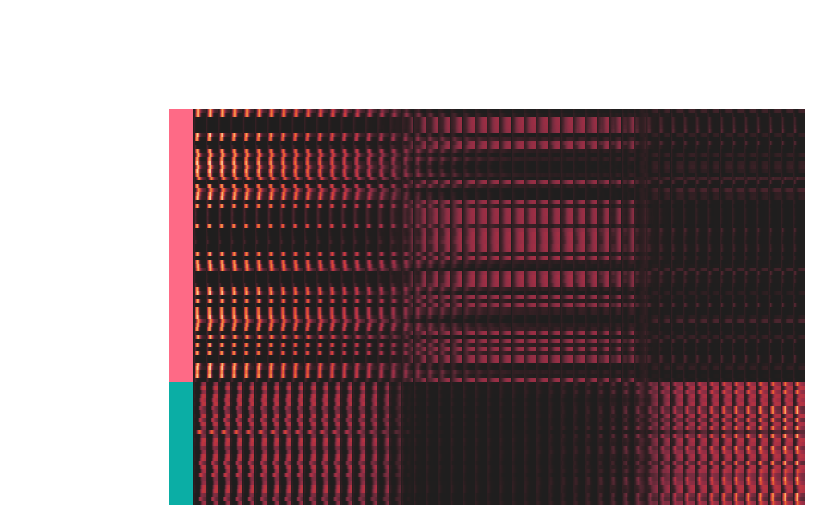

In [36]:
## RESPONSE MATRIX
from Experiment_9.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=25)
x = net(u).detach().cpu().numpy()

x = iterative_outlier_detection(x,2)
x = x[:,:,:]
# Response matrix
rows = []
for k in range(x.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T


# z_score
# responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
# responses = responses[~np.isnan(responses).any(axis=1)]



## CLUSTERED RESPONSE MATRIX
#_,k = compute_k(responses,5,25,.05)
k = 2

clustering = KMeans(n_clusters=k,n_init=20).fit(responses)
labels  = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort,:]
#sorted_responses[:np.sum(labels==0),:] =.8 * sorted_responses[:np.sum(labels==0),:]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)),row_cluster=False, col_cluster=False, row_colors=row_colors,figsize=(8.25,5.25),cbar_pos=None, xticklabels=False, yticklabels=False,center=0)
ax = g.ax_heatmap

g.savefig('Figures/Fig_2afc_b.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

<Axes: >

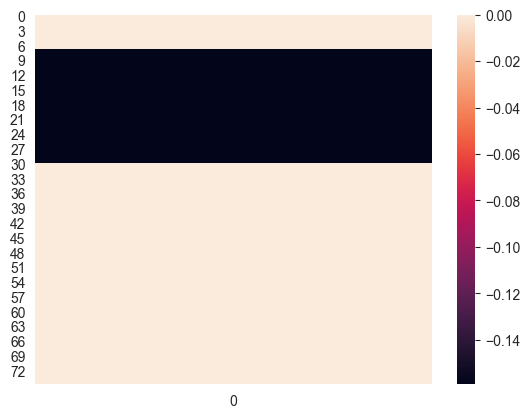

In [58]:
plt.figure()
sns.heatmap(u[2,:,:])

<Axes: ylabel='Count'>

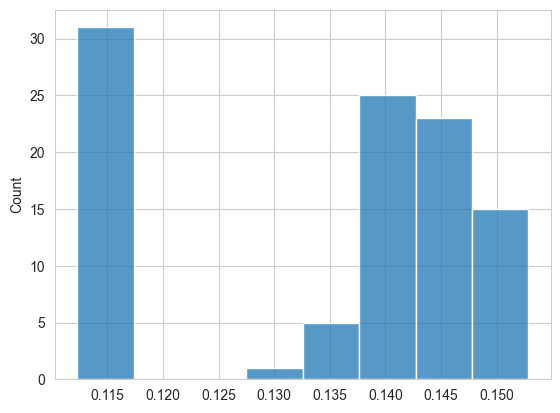

In [38]:
plt.figure()
x = net(u).detach().cpu().numpy()

x = iterative_outlier_detection(x,2)
sns.histplot(x = np.std(x,axis=(0,1)))

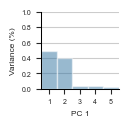

In [39]:
pca = PCA().fit(responses.T)
fig = plt.figure(figsize=(1,1))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.barplot(x = np.arange(1,6),y=pca.explained_variance_ratio_[:5],alpha=.5,ax=ax,width=1)
ax.set_xlabel("PC 1", fontsize=6)
ax.set_ylabel("Variance (%)", fontsize=6)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=5, bottom=True)
ax.yaxis.set_tick_params(labelsize=5, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0,1)
plt.savefig('Figures/Fig1c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight'
            )

In [40]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

net.sigma_in = 0.
net.sigma_rec = 0
#x = lds.output_layer(lds.forward(u))
u, z, mask, conditions  = generate_trials(
                            n_trials=25)
x = net.forward(u)
#x = x-torch.mean(x,dim=[0,1],keepdim=True)
x = x.detach().cpu().numpy()[:,:,:]
n_neurons = x.shape[2]

pca = PCA(n_components=3).fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], 3)
print(x_proj.shape)
rows = []
for k in range(x.shape[0]):
    for t in range(x_proj.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1],
                     'z_3': x_proj[k, t, 2],})
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()


fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])


z = new_df_mean.z_3.values

y = new_df_mean.z_2.values
x = new_df_mean.z_1.values

fig.add_trace(go.Scatter3d(x=x, y=y, z=z,mode='markers',opacity = .25,marker=dict(size=1)))




(1250, 75, 3)


In [ ]:
np.sum(pca.explained_variance_ratio_[2:])

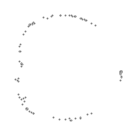

In [25]:
## LDA

pca = PCA()
pca.fit(responses, labels)
x_proj = pca.transform(responses)
x_proj = x_proj #+ 3*(2*np.random.rand(x_proj.shape[0],x_proj.shape[1])-1)

lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)

fig = plt.figure(figsize=(1.5,1.5))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
# sns.scatterplot(x=x_proj[np.argsort(labels), 0], y=x_proj[np.argsort(labels), 1], color=row_colors,s=6,alpha=1,ax=ax)
sns.scatterplot(x=x_proj[np.argsort(labels), 0], y=x_proj[np.argsort(labels), 1], color='gray',s=2,alpha=1,ax=ax)
centers_proj = pca.transform(clustering.cluster_centers_)

#sns.scatterplot(x=centers_proj[:, 0], y=centers_proj[:, 1], color='k',s=3,alpha=1,ax=ax,edgecolor=None)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=8,bottom=True)
ax.yaxis.set_tick_params(labelsize=8,left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
# ax.set_xlim(-30,30)
# ax.set_ylim(-30,30)
plt.savefig('Figures/Fig1c.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

In [26]:
# Get trajectories
from Experiment_9.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=5)
palette = sns.husl_palette(s=1,n_colors=50)

net.sigma_in = 0.
net.sigma_rec = 0
#x = lds.output_layer(lds.forward(u))
x = net.forward(u)
#x = x-torch.mean(x,dim=[0,1],keepdim=True)
x = x.detach().cpu().numpy()[:,:,:]
n_neurons = x.shape[2]

pca = PCA(n_components=2).fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], 2)
rows = []
for k in range(x.shape[0]):
    for t in range(x.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_84976/4195482509.py:64: DeprecationWarning:

__array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)



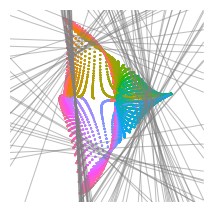

In [27]:
# Get trajectories
from Experiment_9.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=5)
palette = sns.husl_palette(s=1,n_colors=50)

net.sigma_in = 0.
net.sigma_rec = 0
#x = lds.output_layer(lds.forward(u))
x = net.forward(u)
#x = x-torch.mean(x,dim=[0,1],keepdim=True)
x = x.detach().cpu().numpy()[:,:,:]
n_neurons = x.shape[2]

pca = PCA(n_components=2).fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], 2)
rows = []
for k in range(x.shape[0]):
    for t in range(x.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()

fig = plt.figure(figsize=(2.5,2.5))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])



#
sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=1,hue = 't', alpha=.5,palette =sns.light_palette("gray",as_cmap=True))

#sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=4, alpha=1)
sns.scatterplot(data=new_df[new_df.t>0],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)

# sns.scatterplot(data=new_df[new_df.t==15],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#
# sns.scatterplot(data=new_df[new_df.t==30],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#
# sns.scatterplot(data=new_df[new_df.t>70],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=.25,alpha=.25,palette = palette,edgecolor=None)
lims = [
        1*np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
        1*np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
    ]
# ax.set_aspect('equal')
# ax.set_xlim(lims)
# ax.set_ylim(lims)

# Plot restriction of hyperplanes to subspace

# Get first two principal components
U = pca.components_.T

# Get connectiivity
w = net.recurrent_layer.weight.data
b = net.recurrent_layer.bias.data


# Restrict recurrent connectivity to subspace defined by U.
H = w @ U
shift = b
#shift = 0

# # Hyperplanes
lim =3
xx,yy = np.linspace(lims[0],lims[1]), np.linspace(lims[0],lims[1])
x,y = np.meshgrid(xx,yy)
for i in range(n_neurons):
    ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+shift[i].numpy(), [0],colors='gray',linewidths=.75,alpha=.5)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
ax.xaxis.set_tick_params(labelsize=7, bottom=False)
ax.yaxis.set_tick_params(labelsize=7, left=False)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Fig1c.jpg',
    format='jpeg',
    transparent=True,
    dpi=450,
            bbox_inches='tight'
)

In [ ]:
## Tuning maps
u, z, mask, conditions  = generate_trials(
                            n_trials=5,n_conditions = 75)



net.sigma_in=0.1
net.sigma_rec = 0.015
x = net(u).detach()[:,7:,:]
u = u[:,7:,:]
x = (x-torch.mean(x,dim=[0,1],keepdims=True))/ torch.std(x,dim=[0,1],keepdims=True)

rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        for neuron in range(x.shape[2]):
            rows.append({'trial':k,
                         'theta':conditions[k]['theta'],
                        't':t,
                         'neuron'  :neuron,
                        'x':x[k,t,neuron].item(),
                     })
new_df = pd.DataFrame(rows)
new_df_mean =new_df.groupby(['theta','t','neuron']).mean().reset_index()


In [ ]:
plt.figure(figsize=(1.5,1.5))
data = new_df_mean[new_df_mean.neuron== 10]

pivot_df = data.pivot(index='theta', columns='t', values='x')

# Convert the pivoted DataFrame to a 2D NumPy array
array_2d = pivot_df.values

sns.heatmap(array_2d,center=0,cmap='gist_grey',xticklabels=False,yticklabels=False,cbar=False)


plt.savefig('Figures/Exp_2_Fig_2.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight')

In [ ]:
np.argwhere(clustering.labels_==3)

In [ ]:
x = net.forward(u)
torch.save(x,'z_target.pth')
torch.save(u,'u_target.pth')

In [ ]:
15*15

In [ ]:
import cv2
# Get trajectories
net.sigma_in = 0.
net.sigma_rec = 0
palette = sns.husl_palette(s=1,n_colors=35)

u, z, mask, conditions  = generate_trials(
                            n_trials=5,n_conditions = 35)
x = net.forward(u)
n_neurons = x.shape[2]

# Fit PCA to trajectories
pca = PCA(n_components = 2)
pca.fit(x.detach().numpy().reshape(-1,x.shape[2]))

# Project trajectories
proj_rates = pca.transform(x.detach().reshape(-1,x.shape[2]))
proj_rates = proj_rates.reshape(-1,x.shape[1],2)
x = net.forward(u).detach().cpu().numpy()
center = np.mean(x,axis=(0,1))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], 2)
rows = []
for k in range(x.shape[0]):
    for t in range(x.shape[1]):
        rows.append({'trial': k,
                     'theta_1': conditions[k]['theta_1'],
                     'theta_2': conditions[k]['theta_2'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta_1','theta_2', 't']).mean().reset_index()

frames = []

for t in range(50):
    print(t)
    fig = plt.figure(figsize=(2,2))
    gs = gridspec.GridSpec(1,1)

    ax=fig.add_subplot(gs[0,0])


    #
    sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=1,hue = 't', alpha=.5,palette =sns.light_palette("gray",as_cmap=True))

    #sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=4, alpha=1)
    sns.scatterplot(data=new_df_mean[new_df_mean.t==t],x='z_1',y='z_2',hue='theta_1',ax=ax,legend=False,s=1,alpha=1,palette = palette,edgecolor=None)
    #


    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_xlabel("PC 1", fontsize=7)
    ax.set_ylabel("PC 2", fontsize=7)
    ax.xaxis.set_tick_params(labelsize=7, bottom=False)
    ax.yaxis.set_tick_params(labelsize=7, left=False)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)

    plt.savefig('Figures/Fig_'+str(t)+'.jpg',
        format='jpeg',
        transparent=True,
        dpi=450,
                bbox_inches='tight'
    )

    frame = cv2.imread('Figures/Fig_'+str(t)+'.jpg', cv2.IMREAD_COLOR)
    frames.append(frame)
    plt.close()
    # env.step(env.action_space.sample()) # take a random action


import cv2
import numpy as np


def create_video_from_rgb(rgb_data, output_path, fps=30):
    if not rgb_data:
        print("Error: RGB data is empty.")
        return

    height, width, _ = rgb_data[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # or 'XVID'
    video = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    for frame in rgb_data:
        video.write(frame)

    video.release()
    print(f"Video saved to: {output_path}")


# Example usage:
output_video_path = "output_video.mp4"
create_video_from_rgb(frames, output_video_path)

In [ ]:
proj_rates.shape

In [ ]:

net.beta = 10
# Function for calculating curvature vector at a point
def curvature(net,x):
    a = net.recurrent_layer.weight
    f = - x + net.activation(net.recurrent_layer(x))

    c = ( a.t() @ f.t()) ** 2 * torch.exp(net.beta * (net.recurrent_layer(x))) / (1 + torch.exp(net.beta * (net.recurrent_layer(x)) ))**2
    return c

x = net.forward(u)

x = x.detach().cpu().numpy()
center =  np.mean(x.reshape(-1,x.shape[2]),axis=0)
rows = []
for x in np.linspace(lims[0],lims[1],200):
    for y in np.linspace(lims[0],lims[1],200):
        # Get state
        z= torch.tensor(U@np.array([[x],[y]]) ).float().t()

        # Calculate curvature at state
        c =  curvature(net,z)
        mag = torch.linalg.norm(c)
        # Project curvature vector onto first two PCS.
        c_proj = pca.transform(c.detach().numpy())

        rows.append({'x':-y.item(),
                     'y':x.item(),
                     'mag':mag.item()})
df = pd.DataFrame(rows)

fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1)

ax=fig.add_subplot(gs[0,0])
pivot_df = df.pivot_table(index='x', columns='y', values='mag')

# Convert the pivot table to a 2D NumPy array
two_d_array = pivot_df.to_numpy()

sns.heatmap(two_d_array,cmap='Greys_r',ax=ax,cbar=False,xticklabels=False,yticklabels=False)

        # Calculate curvature at this state.


plt.savefig('Figures/Fig1c.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)



In [ ]:
u, z, mask, conditions  = generate_trials(
                            n_trials=50)



net.sigma_in=0
net.sigma_rec = 0
x = net(u)

output = net.output_layer(x).detach().numpy()
rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial':k,
                     'theta':conditions[k]['theta'],
                    't':t,
                    'z_1':output[k,t,0].item(),
                    'z_2':output[k,t,1].item(),
                     'target_1':z[k,t,0].item(),
                    'target_2':z[k,t,1].item(),})
new_df = pd.DataFrame(rows)
new_df_mean =new_df.groupby(['theta','t']).mean().reset_index()
fig = plt.figure(figsize=(1.5,1.5))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])



sns.scatterplot(data=new_df[new_df.t==74],x='z_1',y='z_2',ax=ax,legend=False,s=6,alpha=1,hue='theta',palette = palette)

sns.scatterplot(data=new_df[new_df.t==74],x='target_1',y='target_2',ax=ax,legend=False,s=6,alpha=1,color='gray')

# Plot targets



ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1",fontsize=7)
ax.set_ylabel("PC 2",fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7,bottom=True)
ax.yaxis.set_tick_params(labelsize=7,left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]


fig.savefig('Figures/Exp_2_Fig_2.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight')


In [ ]:
## Tuning maps
u, z, mask, conditions  = generate_trials(
                            n_trials=5,n_conditions = 75)



net.sigma_in=0.1
net.sigma_rec = 0.015
x = net(u).detach()
x = (x-torch.mean(x,dim=[0,1],keepdims=True))/ torch.std(x,dim=[0,1],keepdims=True)

rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        for neuron in range(x.shape[2]):
            rows.append({'trial':k,
                         'theta':conditions[k]['theta'],
                        't':t,
                         'neuron'  :neuron,
                        'x':x[k,t,neuron].item(),
                     })
new_df = pd.DataFrame(rows)
new_df_mean =new_df.groupby(['theta','t','neuron']).mean().reset_index()

plt.figure(figsize=(1.5,1.5))
data = new_df_mean[new_df_mean.neuron==17]

pivot_df = data.pivot(index='theta', columns='t', values='x')

# Convert the pivoted DataFrame to a 2D NumPy array
array_2d = pivot_df.values

sns.heatmap(array_2d,center=0,cmap='Greys_r',xticklabels=False,yticklabels=False,cbar=False)


plt.savefig('Figures/Exp_2_Fig_2.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight')

In [ ]:
?data

In [ ]:
model_data = original_df[original_df.model_id=='PROzVPh5']
net = Net(n=100,input_size = 2,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2)
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2)
net.sigma_in = 0.0
from Experiment_7.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=25)

In [ ]:
# PRactive

In [9]:
from Experiment_9.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=25)

net = Net(n=100, input_size=1,output_size=u.shape[2],
              dale=False,
              sigma_in=0,
              base_in=0,
              lambda_std=.4,
              beta=10).to(device)

# Fit with penalty
lds = net.fit(u.to(device=device),
        z.to(device=device),
        mask.to(device=device),
        lr=.005,
        epochs=1000,
        conditions=conditions,
        verbose=True,
        lvar=2,
        dim=2,
        weight_decay=.001,
        kmeans_target=0.25,
        pca_target_1=.5,
        pca_target_2=0,
        linear_target=.5,
        lambda_kmeans=1,
        lambda_pca_1=1,
        lambda_pca_2=1,
        lambda_linear=1,

              )

Epoch: 50/1000............. mse_z: 0.9984 kmeans: 0.2517 pca: 0.0382 snr: 0.3122 lds: 0.5872
Epoch: 100/1000............. mse_z: 0.9962 kmeans: 0.2652 pca: 0.0275 snr: 0.2716 lds: 0.4980
Epoch: 150/1000............. mse_z: 0.9999 kmeans: 0.2796 pca: 0.0285 snr: 0.2528 lds: 0.4260
Epoch: 200/1000............. mse_z: 0.9988 kmeans: 0.2555 pca: 0.0279 snr: 0.2626 lds: 0.5091
Epoch: 250/1000............. mse_z: 1.0054 kmeans: 0.2546 pca: 0.0283 snr: 0.2573 lds: 0.5537
Epoch: 300/1000............. mse_z: 1.0199 kmeans: 0.2547 pca: 0.0317 snr: 0.2046 lds: 0.5016
Epoch: 350/1000............. mse_z: 1.0340 kmeans: 0.2496 pca: 0.0296 snr: 0.1779 lds: 0.5073
Epoch: 400/1000............. mse_z: 0.9856 kmeans: 0.2474 pca: 0.0293 snr: 0.1292 lds: 0.5035
Epoch: 450/1000............. mse_z: 0.9857 kmeans: 0.2522 pca: 0.0327 snr: 0.1222 lds: 0.4800
Epoch: 500/1000............. mse_z: 0.9997 kmeans: 0.2441 pca: 0.0352 snr: 0.1423 lds: 0.5322
Epoch: 550/1000............. mse_z: 1.0182 kmeans: 0.2498 pca

In [10]:
# Get trajectories
from Experiment_9.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=5,n_conditions = 200)
palette = sns.husl_palette(s=1,n_colors=200)

net.sigma_in = 0.
net.sigma_rec = 0
#x = lds.output_layer(lds.forward(u))
x = net.forward(u)
#x = x-torch.mean(x,dim=[0,1],keepdim=True)
x = x.detach().cpu().numpy()[:,:,:]
n_neurons = x.shape[2]

pca = PCA(n_components=2).fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], 2)
rows = []
for k in range(x.shape[0]):
    for t in range(x.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_84976/2051466130.py:37: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  H = w @ U


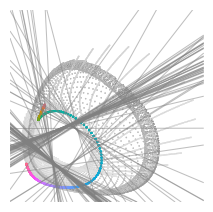

In [16]:

fig = plt.figure(figsize=(2.5,2.5))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])



#
sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=1,hue = 't', alpha=.5,palette =sns.light_palette("gray",as_cmap=True))

#sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=4, alpha=1)
sns.scatterplot(data=new_df[new_df.t==30],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)

# sns.scatterplot(data=new_df[new_df.t==15],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#
# sns.scatterplot(data=new_df[new_df.t==30],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#
# sns.scatterplot(data=new_df[new_df.t>70],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=.25,alpha=.25,palette = palette,edgecolor=None)
lims = [
        1*np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
        1*np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
    ]
# ax.set_aspect('equal')
# ax.set_xlim(lims)
# ax.set_ylim(lims)

# Plot restriction of hyperplanes to subspace

# Get first two principal components
U = pca.components_.T

# Get connectiivity
w = net.recurrent_layer.weight.data
b = net.recurrent_layer.bias.data


# Restrict recurrent connectivity to subspace defined by U.
H = w @ U
shift = b
#shift = 0

# # Hyperplanes
lim =3
xx,yy = np.linspace(lims[0],lims[1]), np.linspace(lims[0],lims[1])
x,y = np.meshgrid(xx,yy)
for i in range(n_neurons):
    ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+shift[i].numpy(), [0],colors='gray',linewidths=.75,alpha=.5)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
ax.xaxis.set_tick_params(labelsize=7, bottom=False)
ax.yaxis.set_tick_params(labelsize=7, left=False)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Fig1c.jpg',
    format='jpeg',
    transparent=True,
    dpi=450,
            bbox_inches='tight'
)

In [28]:
frames = []
import cv2
import numpy as np
for t in range(50):
    print(t)
    fig = plt.figure(figsize=(2,2))
    gs = gridspec.GridSpec(1,1)

    ax=fig.add_subplot(gs[0,0])


    #
    sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=1,hue = 't', alpha=.5,palette =sns.light_palette("gray",as_cmap=True))

    #sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=4, alpha=1)
    sns.scatterplot(data=new_df_mean[new_df_mean.t==t],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=1,alpha=1,palette = palette,edgecolor=None)
    #


    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_xlabel("PC 1", fontsize=7)
    ax.set_ylabel("PC 2", fontsize=7)
    ax.xaxis.set_tick_params(labelsize=7, bottom=False)
    ax.yaxis.set_tick_params(labelsize=7, left=False)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)

    plt.savefig('Figures/Fig_'+str(t)+'.jpg',
        format='jpeg',
        transparent=True,
        dpi=450,
                bbox_inches='tight'
    )

    frame = cv2.imread('Figures/Fig_'+str(t)+'.jpg', cv2.IMREAD_COLOR)
    frames.append(frame)
    plt.close()

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49


In [29]:
def create_video_from_rgb(rgb_data, output_path, fps=30):
    if not rgb_data:
        print("Error: RGB data is empty.")
        return

    height, width, _ = rgb_data[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # or 'XVID'
    video = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    for frame in rgb_data:
        video.write(frame)

    video.release()
    print(f"Video saved to: {output_path}")


# Example usage:
output_video_path = "output_video.mp4"
create_video_from_rgb(frames, output_video_path)

Video saved to: output_video.mp4


In [33]:

x = torch.tensor(x).float().to(device)
linear_errors = []
for _ in range(5):
    lds = LDS(n=25, input_size = 1,output_size=x.shape[2]).to(device=device)
    lds.fit(u.to(device=device), x, epochs=1000)
    y = lds.output_layer(lds(u.to(device=device)))
    linear_error = net.linear_error(y, x).detach().item()
    linear_errors.append(linear_error)
linear_error = np.min(linear_errors)


NameError: name 'compute_kmeans_error' is not defined

In [34]:
linear_error

np.float64(0.5531930327415466)